# Amount Baseline and Model Comparison

**Research question:** Can Bagging PU recover more held-out labeled wallets than amount ranking at the same review threshold?


## 1. Setup

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path/'wallet_features.csv').is_file()
             and (path/'pu_bagging_leave_one_insider_out.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the full repository and open this notebook from its root folder.')
DATA_PATH = ROOT/'wallet_features.csv'
RESULT_DIR = ROOT/'outputs/model_comparison/results'
FIGURE_DIR = ROOT/'outputs/model_comparison/figures'
for folder in [RESULT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print('Python version:', platform.python_version())


Python version: 3.12.14


## 2. Data Validation

In [2]:
df = pd.read_csv(DATA_PATH)
required = ['wallet', 'total_notional', 'confirmed', 'trade_count', 'unique_markets']
assert set(required).issubset(df.columns), 'Required columns are missing.'
assert df.wallet.notna().all() and df.wallet.is_unique, 'Wallet IDs are missing or duplicated.'
label = df.confirmed.astype(str).str.lower().str.strip()
assert label.isin(['true','false','1','0']).all(), 'The confirmed column contains unrecognized values.'
df['confirmed'] = label.isin(['true','1'])
for col in ['total_notional','trade_count','unique_markets']:
    df[col] = pd.to_numeric(df[col], errors='raise')
    assert df[col].notna().all() and df[col].ge(0).all(), f'{col} contains invalid values.'
print('Total wallets:', len(df), '; Known-positive wallets:', int(df.confirmed.sum()))
assert not df.isna().any().any(), 'Missing feature values require review.'


Total wallets: 55952 ; Known-positive wallets: 19


## 3. Analysis Population

In [3]:
population = df.copy()
print('Wallets included:', len(population))
print('Known-positive wallets:', int(population.confirmed.sum()))
print('Excluded wallets:', len(df) - len(population))

Wallets included: 55952
Known-positive wallets: 19
Excluded wallets: 0


## 4. Amount Ranking

In [4]:
ranking = population.sort_values(['total_notional','wallet'], ascending=[False,True]).copy()
ranking['rank'] = range(1, len(ranking)+1)
ranking[['wallet','total_notional','confirmed','rank']].to_csv(RESULT_DIR/'baseline_ranking.csv', index=False)
display(ranking[['rank','wallet','total_notional','confirmed']].head(10))


,rank,wallet,total_notional,confirmed
33066,1,w_fceb6ba618,1.971762e+07,False
51928,2,w_1eba4c9fe9,1.408911e+07,False
43988,3,w_558c6206a8,1.325751e+07,False
40935,4,w_a855751ddf,7.262936e+06,False
8089,5,w_b392bf03fb,7.118185e+06,False
43148,6,w_e28f7c7158,5.799982e+06,False
37572,7,w_88cf3a76a8,5.535107e+06,False
27299,8,w_4f5cbbd869,5.326783e+06,False
19469,9,w_32e0ab777b,4.960324e+06,False
30294,10,w_8d84a6bd86,4.577770e+06,False


## 5. Baseline Evaluation

In [5]:
import numpy as np
import hashlib
import json

SPLIT_SEED = 0
pos = np.flatnonzero(population.confirmed.to_numpy())
unl = np.flatnonzero(~population.confirmed.to_numpy())
spend = population.total_notional.to_numpy()
wallet_ids = population.wallet.to_numpy()
rng = np.random.default_rng(SPLIT_SEED)
fold_rows = []
for i in pos:
    test_unl = rng.choice(unl, size=len(unl) // 5, replace=False)
    spend_pct = float(np.mean(spend[test_unl] >= spend[i]))
    fold_rows.append(dict(
        insider=wallet_ids[i], spend_pct=spend_pct,
        test_unlabeled_count=len(test_unl), test_wallet_count=len(test_unl)+1,
        split_seed=SPLIT_SEED,
        test_unlabeled_indices_sha256=hashlib.sha256(
            test_unl.astype('<i8').tobytes()).hexdigest()))
fold_results = pd.DataFrame(fold_rows)
fold_results.to_csv(RESULT_DIR/'baseline_loio_per_wallet.csv', index=False)

rows = []
for fraction in [0.005, 0.01, 0.025, 0.05, 0.10]:
    hits = int((fold_results.spend_pct <= fraction).sum())
    rows.append(dict(method='Amount baseline (LOIO)', review_fraction=fraction,
                     known_hits=hits, positive_total=len(pos), recall=hits/len(pos)))
summary = pd.DataFrame(rows)
summary.to_csv(RESULT_DIR/'baseline_loio_summary.csv', index=False)
metadata = dict(split_seed=SPLIT_SEED, bot_filter=False,
                source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
                population_size=len(population), known_positive_count=len(pos),
                percentile_definition='mean(test_unlabeled_notional >= held_out_positive_notional)',
                note='Amount baseline evaluated on the same test pools as the PU models.')
(RESULT_DIR/'baseline_loio_metadata.json').write_text(json.dumps(metadata, indent=2))
print('Evaluation folds:', len(fold_results))
print('Test wallets per fold:', fold_results.test_wallet_count.unique())
display(summary)


Evaluation folds: 19
Test wallets per fold: [11187]


,method,review_fraction,known_hits,positive_total,recall
0,Amount baseline (LOIO),0.005,3,19,0.157895
1,Amount baseline (LOIO),0.010,5,19,0.263158
2,Amount baseline (LOIO),0.025,8,19,0.421053
3,Amount baseline (LOIO),0.050,12,19,0.631579
4,Amount baseline (LOIO),0.100,16,19,0.842105


## 6. Baseline Recall

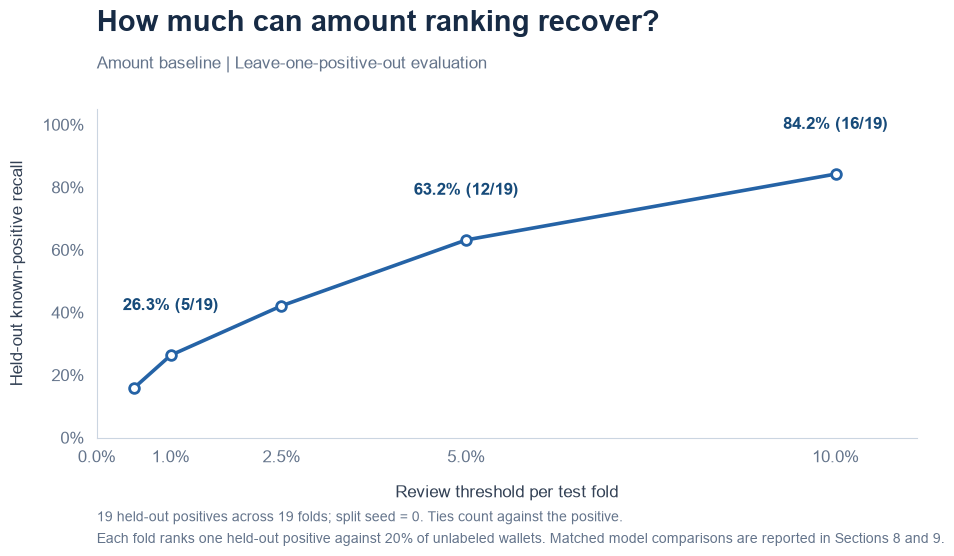

In [6]:
from matplotlib.ticker import PercentFormatter

# Single-panel baseline figure; all five evaluation thresholds are retained.
# Values summarize one fixed split seed, not repeated-run uncertainty.
with plt.rc_context({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'font.size': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#CBD5E1', 'axes.labelcolor': '#334155',
    'xtick.color': '#64748B', 'ytick.color': '#64748B',
    'pdf.fonttype': 42, 'svg.fonttype': 'none'
}):
    fig, ax = plt.subplots(figsize=(10, 6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.94, bottom=0.23, top=0.76)
    x = summary.review_fraction.to_numpy() * 100
    y = summary.recall.to_numpy() * 100
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.plot(x, y, color='#2563A6', linewidth=2.6, marker='o', markersize=7,
            markerfacecolor='white', markeredgewidth=2, zorder=3)
    for fraction in [0.01, 0.05, 0.10]:
        row = summary.loc[np.isclose(summary.review_fraction, fraction)].iloc[0]
        ax.annotate(f"{row.recall:.1%} ({int(row.known_hits)}/19)",
                    (fraction*100, row.recall*100), xytext=(0, 30),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=12, fontweight='bold', color='#174B7A')
    ax.set(xlim=(0, 11.1), ylim=(0, 105),
           xlabel='Review threshold per test fold',
           ylabel='Held-out known-positive recall')
    ax.set_xticks([0, 1, 2.5, 5, 10])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis='both', length=0, pad=9)
    ax.xaxis.labelpad = 14
    ax.yaxis.labelpad = 12
    fig.text(0.12, 0.92, 'How much can amount ranking recover?',
             fontsize=21, fontweight='bold', color='#172B45', va='top')
    fig.text(0.12, 0.845, 'Amount baseline | Leave-one-positive-out evaluation',
             fontsize=12, color='#64748B', va='top')
    fig.text(0.12, 0.095,
             '19 held-out positives across 19 folds; split seed = 0. Ties count against the positive.',
             fontsize=10, color='#64748B')
    fig.text(0.12, 0.06,
             'Each fold ranks one held-out positive against 20% of unlabeled wallets. Matched model comparisons are reported in Sections 8 and 9.',
             fontsize=10, color='#64748B')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.png', dpi=300, facecolor='white')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.pdf', facecolor='white')
    fig.savefig(FIGURE_DIR/'baseline_recall_LOIO.svg', facecolor='white')
    plt.show()


## 7. Bagging PU and Matched Evaluation

In [7]:
import importlib.util
import sklearn
from threadpoolctl import threadpool_limits

MODEL_PATH = ROOT/'pu_bagging_leave_one_insider_out.py'
spec = importlib.util.spec_from_file_location('team_pu_model', MODEL_PATH)
pu = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pu)
W, X, y = pu.load(DATA_PATH)
assert W.index.tolist() == population.wallet.tolist(), 'Wallet order mismatch.'
assert np.array_equal(y, population.confirmed.to_numpy()), 'Label mismatch.'
Z = pu.standardize(X)
positive_indices = np.flatnonzero(y)
unlabeled_indices = np.flatnonzero(~y)
spend = W.total_notional.to_numpy()
PU_SEED = 0
model_rows = []

# Retrain every run. No precomputed result files are required.
with threadpool_limits(limits=1):
    for fold, (i, test_unlabeled) in enumerate(
            pu.make_folds(positive_indices, unlabeled_indices, SPLIT_SEED), start=1):
        train_positive = np.setdiff1d(positive_indices, [i])
        train_unlabeled = np.setdiff1d(unlabeled_indices, test_unlabeled)
        test = np.r_[test_unlabeled, i]
        row = {'insider': W.index[i],
               'spend_pct': float(np.mean(spend[test_unlabeled] >= spend[i]))}
        for base, features in [('tree', X), ('logistic', Z)]:
            scores, _ = pu.bagging_pu(features[train_positive], features[train_unlabeled],
                                    features[test], PU_SEED, base)
            row[f'{base}_pct'], row[f'{base}_pct_ties_split'] = pu.percentiles(scores[:-1], scores[-1])
        model_rows.append(row)
        print(f'Completed fold {fold}/{len(positive_indices)}')
model_folds = pd.DataFrame(model_rows)
model_folds.to_csv(RESULT_DIR/'pu_loio_per_wallet.csv', index=False)
matched = fold_results.merge(model_folds, on='insider',
                            suffixes=('_baseline', '_model'), validate='one_to_one')
assert len(matched) == len(positive_indices)
assert np.allclose(matched.spend_pct_baseline, matched.spend_pct_model,
                   rtol=0, atol=1e-14), 'Baseline mismatch.'
comparison_rows = []
for method, column in [('Amount ranking', 'spend_pct'), ('Bagging PU - Tree', 'tree_pct'),
                       ('Bagging PU - Logistic', 'logistic_pct')]:
    for fraction in [0.005, 0.01, 0.025, 0.05, 0.10]:
        hits = int((model_folds[column] <= fraction).sum())
        comparison_rows.append(dict(method=method, review_fraction=fraction,
                                    known_hits=hits, positive_total=len(positive_indices),
                                    recall=hits/len(positive_indices)))
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULT_DIR/'model_comparison_summary.csv', index=False)
run_metadata = dict(split_seed=SPLIT_SEED, pu_seed=PU_SEED, K=pu.K, T=pu.T, depth=pu.DEPTH,
                    data_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
                    model_sha256=hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(),
                    python=platform.python_version(), sklearn=sklearn.__version__,
                    baseline_match=True)
(RESULT_DIR/'run_metadata.json').write_text(json.dumps(run_metadata, indent=2))
print('Baseline check passed for all test folds.')
display(comparison.loc[comparison.review_fraction.isin([0.01, 0.05, 0.10])].reset_index(drop=True))


Completed fold 1/19


Completed fold 2/19


Completed fold 3/19


Completed fold 4/19


Completed fold 5/19


Completed fold 6/19


... (10 outputs left out)

Completed fold 17/19


Completed fold 18/19


Completed fold 19/19
Baseline check passed for all test folds.


,method,review_fraction,known_hits,positive_total,recall
0,Amount ranking,0.01,5,19,0.263158
1,Amount ranking,0.05,12,19,0.631579
2,Amount ranking,0.10,16,19,0.842105
3,Bagging PU - Tree,0.01,9,19,0.473684
4,Bagging PU - Tree,0.05,14,19,0.736842
5,Bagging PU - Tree,0.10,16,19,0.842105
6,Bagging PU - Logistic,0.01,10,19,0.526316
7,Bagging PU - Logistic,0.05,17,19,0.894737
8,Bagging PU - Logistic,0.10,18,19,0.947368


## 8. Recovery at 1%

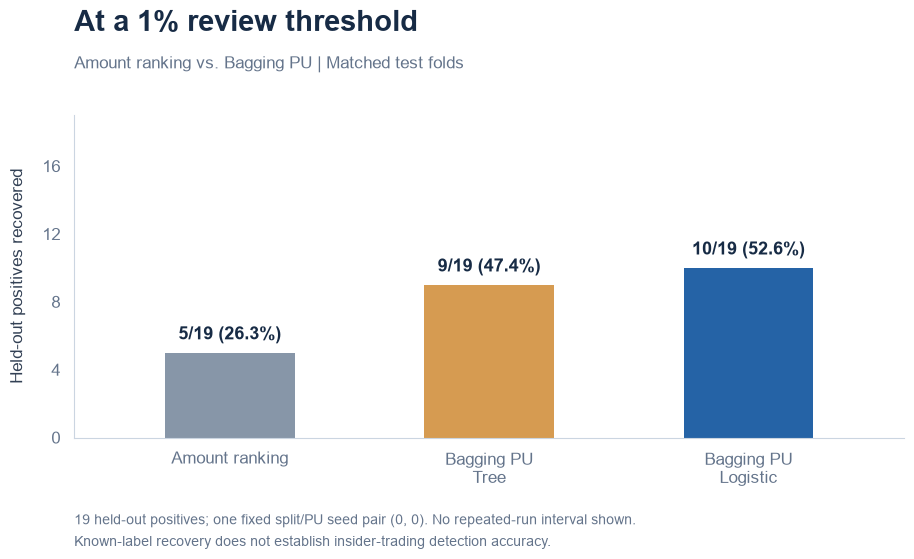

In [8]:
from matplotlib.ticker import MaxNLocator

METHODS = ['Amount ranking', 'Bagging PU - Tree', 'Bagging PU - Logistic']
COLORS = ['#8796A8', '#D69B51', '#2563A6']
PLOT_STYLE = {'font.family': 'sans-serif', 'font.sans-serif': ['Arial','DejaVu Sans'],
              'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False,
              'axes.edgecolor': '#CBD5E1', 'axes.labelcolor': '#334155',
              'xtick.color': '#64748B', 'ytick.color': '#64748B',
              'pdf.fonttype': 42, 'svg.fonttype': 'none'}

top_one = comparison.loc[np.isclose(comparison.review_fraction, 0.01)].set_index('method').loc[METHODS]
with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(10,6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.95, bottom=0.23, top=0.75)
    positions = np.arange(len(METHODS))
    ax.bar(positions, top_one.known_hits, width=0.5, color=COLORS)
    for position, (_, row) in zip(positions, top_one.iterrows()):
        ax.text(position, row.known_hits+0.55, f'{int(row.known_hits)}/19 ({row.recall:.1%})',
                ha='center', va='bottom', fontsize=13, fontweight='bold', color='#172B45')
    ax.set_xticks(positions, ['Amount ranking','Bagging PU\nTree','Bagging PU\nLogistic'])
    ax.set(xlim=(-0.6,2.6), ylim=(0,19), ylabel='Held-out positives recovered')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
    ax.tick_params(length=0, pad=10)
    ax.yaxis.labelpad=12
    fig.text(0.12,0.92,'At a 1% review threshold',fontsize=21,fontweight='bold',color='#172B45',va='top')
    fig.text(0.12,0.845,'Amount ranking vs. Bagging PU | Matched test folds',fontsize=12,color='#64748B',va='top')
    fig.text(0.12,0.09,'19 held-out positives; one fixed split/PU seed pair (0, 0). No repeated-run interval shown.',fontsize=10,color='#64748B')
    fig.text(0.12,0.055,'Known-label recovery does not establish insider-trading detection accuracy.',fontsize=10,color='#64748B')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.png',dpi=300,facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.pdf',facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_top1.svg',facecolor='white')
    plt.show()


## 9. Recall across Review Thresholds

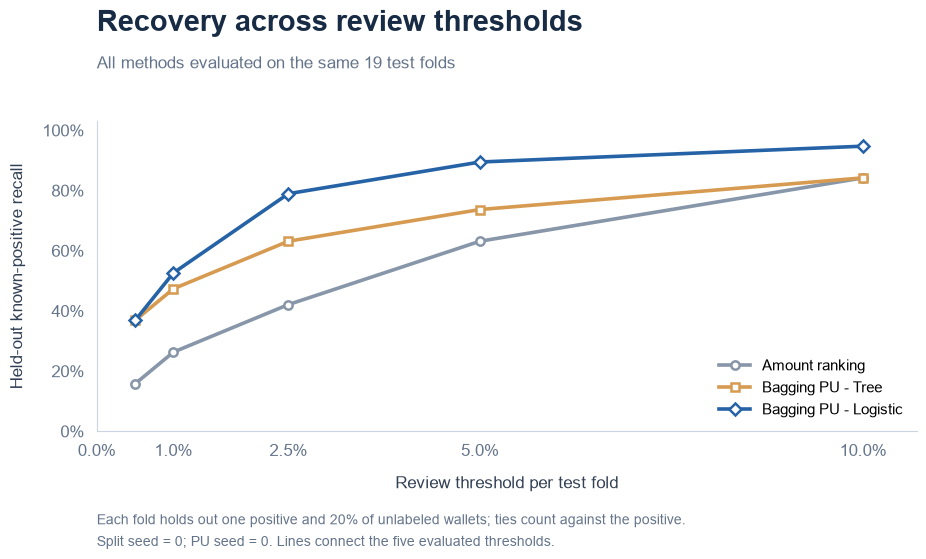

In [9]:
from matplotlib.ticker import PercentFormatter

with plt.rc_context(PLOT_STYLE):
    fig, ax = plt.subplots(figsize=(10,6.2), facecolor='white')
    fig.subplots_adjust(left=0.12, right=0.94, bottom=0.24, top=0.74)
    for method, color, marker in zip(METHODS,COLORS,['o','s','D']):
        part = comparison.loc[comparison.method.eq(method)].sort_values('review_fraction')
        ax.plot(part.review_fraction*100, part.recall*100, color=color, marker=marker,
                linewidth=2.6, markersize=6, markerfacecolor='white', markeredgewidth=1.8,
                label=method)
    ax.set(xlim=(0,10.7),ylim=(0,103),xlabel='Review threshold per test fold',
           ylabel='Held-out known-positive recall')
    ax.set_xticks([0,1,2.5,5,10])
    ax.set_yticks([0,20,40,60,80,100])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(length=0,pad=9)
    ax.xaxis.labelpad=12
    ax.yaxis.labelpad=12
    ax.legend(loc='lower right',frameon=False,fontsize=11)
    fig.text(0.12,0.92,'Recovery across review thresholds',fontsize=21,fontweight='bold',color='#172B45',va='top')
    fig.text(0.12,0.845,'All methods evaluated on the same 19 test folds',fontsize=12,color='#64748B',va='top')
    fig.text(0.12,0.09,'Each fold holds out one positive and 20% of unlabeled wallets; ties count against the positive.',fontsize=10,color='#64748B')
    fig.text(0.12,0.055,'Split seed = 0; PU seed = 0. Lines connect the five evaluated thresholds.',fontsize=10,color='#64748B')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.png',dpi=300,facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.pdf',facecolor='white')
    fig.savefig(FIGURE_DIR/'model_comparison_recall.svg',facecolor='white')
    plt.show()


## 10. Limitations

19 supplied labels, one seed pair, potentially related wallets across folds, and standardization using all feature rows. Results measure known-label recovery. See README for setup and interpretation.
